In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
loanDataFrameTrain1 = pd.read_csv(r"./datafold1/fold_1_train.csv")
loanDataFrameTest1 = pd.read_csv(r"./datafold1/fold_1_test.csv")
loanDataFrameTrain2 = pd.read_csv(r"./datafold2/fold_2_train.csv")
loanDataFrameTest2 = pd.read_csv(r"./datafold2/fold_2_test.csv")
loanDataFrameTrain3 = pd.read_csv(r"./datafold3/fold_3_train.csv")
loanDataFrameTest3 = pd.read_csv(r"./datafold3/fold_3_test.csv")
loanDataFrameTrain4 = pd.read_csv(r"./datafold4/fold_4_train.csv")
loanDataFrameTest4 = pd.read_csv(r"./datafold4/fold_4_test.csv")
loanDataFrameTrain5 = pd.read_csv(r"./datafold5/fold_5_train.csv")
loanDataFrameTest5 = pd.read_csv(r"./datafold5/fold_5_test.csv")

In [4]:
loanDataFrameTrain1

,age,gender_is_male,gender_is_nonbinary,marital_status_married,marital_status_divorced,marital_status_widowed,education_high_school,education_master_degree,education_doctoral_degree,education_is_unknown,...,interest_rate,loan_term,credit_grade_score,num_of_open_accounts,total_credit_limit,current_balance,delinquency_history,public_records,num_of_delinquencies,loan_paid_back
0,59,1,0,1,0,0,0,1,0,0,...,13.39,36,21,7,40833.47,24302.07,1,0,1,1
1,72,0,0,1,0,0,0,0,0,0,...,17.81,60,5,5,27968.01,10803.01,1,0,3,1
2,28,1,0,0,0,0,1,0,0,0,...,12.73,60,25,3,76147.61,14885.25,0,0,1,1
3,41,1,0,0,0,0,0,0,0,0,...,12.48,36,23,6,18380.15,12683.33,3,0,3,0
4,43,0,0,0,0,0,1,0,0,0,...,11.81,36,25,4,40629.06,15965.92,2,0,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15995,70,1,0,1,0,0,0,0,1,0,...,13.82,36,18,5,29026.60,14404.31,0,0,1,1
15996,30,0,0,1,0,0,0,0,0,0,...,11.99,36,22,5,33973.88,16081.00,1,0,1,1
15997,65,0,0,0,0,0,0,1,0,0,...,10.06,36,22,3,13137.57,5075.67,1,0,2,1
15998,35,1,0,1,0,0,0,1,0,0,...,16.06,36,14,5,19580.82,3876.16,4,0,5,1


In [24]:
def preprocess_data(df_train, df_test):
  scaler = StandardScaler()
  X_train_scaled = scaler.fit_transform(df_train.drop(columns=['loan_paid_back']))
  X_test_scaled = scaler.transform(df_test.drop(columns=['loan_paid_back']))
  y_train = df_train['loan_paid_back']
  y_test = df_test['loan_paid_back']

  smote = SMOTE(random_state=42)
  X_train_bal, y_train_bal = smote.fit_resample(X_train_scaled, y_train)

  X_train_bal_df = pd.DataFrame(X_train_bal, columns=df_train.drop(columns=['loan_paid_back']).columns)
  y_train_bal_df = pd.Series(y_train_bal, name="loan_paid_back")
  X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=df_train.drop(columns=['loan_paid_back']).columns)
  y_test_df = pd.Series(y_test.reset_index(drop=True), name="loan_paid_back")

  df_train = pd.concat([X_train_bal_df, y_train_bal_df], axis=1)
  df_test = pd.concat([X_test_scaled_df, y_test_df], axis=1)

  return df_train, df_test

df_train = preprocess_data(loanDataFrameTrain1, loanDataFrameTest1)[0]
df_test = preprocess_data(loanDataFrameTrain1, loanDataFrameTest1)[1]

print(preprocess_data(loanDataFrameTrain1, loanDataFrameTest1)[0]['loan_paid_back'].value_counts())

loan_paid_back
1    12798
0    12798
Name: count, dtype: int64


In [20]:
def binary_cross_entropy(y_pred, y_true):
  result = -torch.mean(y_true * torch.log(y_pred + 1e-7) + (1 - y_true) * torch.log(1 - y_pred + 1e-7))
  if result < 0:
    result = -result
  return result

binary_cross_entropy(torch.tensor([1, 0]), torch.tensor([1, 0]))

tensor(1.1921e-07)

In [19]:
def evaluate_confusion_matrix(y_true, y_pred):
  tp = torch.sum((y_true == 1) & (y_pred == 1)).item()
  tn = torch.sum((y_true == 0) & (y_pred == 0)).item()
  fp = torch.sum((y_true == 0) & (y_pred == 1)).item()
  fn = torch.sum((y_true == 1) & (y_pred == 0)).item()
  return tp, tn, fp, fn

In [21]:
def logistic_regression_model(data_shape):
  model = nn.Sequential(
      nn.Linear(data_shape, 1),
      nn.Sigmoid()
  )
  return model

In [81]:
def train_and_evaluate_model(df_train, df_test, model, epochs, learning_rate):
  X_train = df_train.drop(columns=['loan_paid_back'])
  y_train = df_train['loan_paid_back']
  X_test = df_test.drop(columns=['loan_paid_back'])
  y_test = df_test['loan_paid_back']

  X_train_tensor = torch.tensor(X_train.values, dtype=torch.float32)
  y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32)
  X_test_tensor = torch.tensor(X_test.values, dtype=torch.float32)

  losses = torch.zeros(epochs)
  true_positives = torch.zeros(epochs)
  true_negatives = torch.zeros(epochs)
  false_positives = torch.zeros(epochs)
  false_negatives = torch.zeros(epochs)
  f1_eval = torch.zeros(epochs)
  precision_eval = torch.zeros(epochs)

  optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

  for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()

    y_pred = model(X_train_tensor).squeeze(1)
    loss = binary_cross_entropy(y_pred, y_train_tensor)
    losses[epoch] = loss.item()
    loss.backward()
    optimizer.step()

    model.eval()
    with torch.no_grad():
      y_pred = model(X_test_tensor).squeeze(1)
      y_pred_class = (y_pred >= 0.5).int()
      tp, tn, fp, fn = evaluate_confusion_matrix(torch.tensor(y_test.values), y_pred_class)
      true_positives[epoch] = tp
      true_negatives[epoch] = tn
      false_positives[epoch] = fp
      false_negatives[epoch] = fn
      if (tp + fp) > 0:
        precision = tp / (tp + fp)
      else:
        precision = torch.tensor(0.0)
      if (tp + fn) > 0:
        recall = tp / (tp + fn)
      else:
        recall = torch.tensor(0.0)
      if (precision + recall) > 0:
        f1 = 2 * (precision * recall) / (precision + recall)
      else:
        f1 = torch.tensor(0.0)
      f1_eval[epoch] = f1
      precision_eval[epoch] = precision
    #print(f'Epoch {epoch+1}/{epochs} - Loss: {loss.item():.4f} - F1: {f1:.4f} - Precision: {precision:.4f}')

  return losses, true_positives, true_negatives, false_positives, false_negatives, f1_eval, precision_eval

model = logistic_regression_model(df_train.shape[1]-1)
train_and_evaluate_model(df_train, df_test, model, 100, 0.01)[-2][-1]

tensor(0.8678)

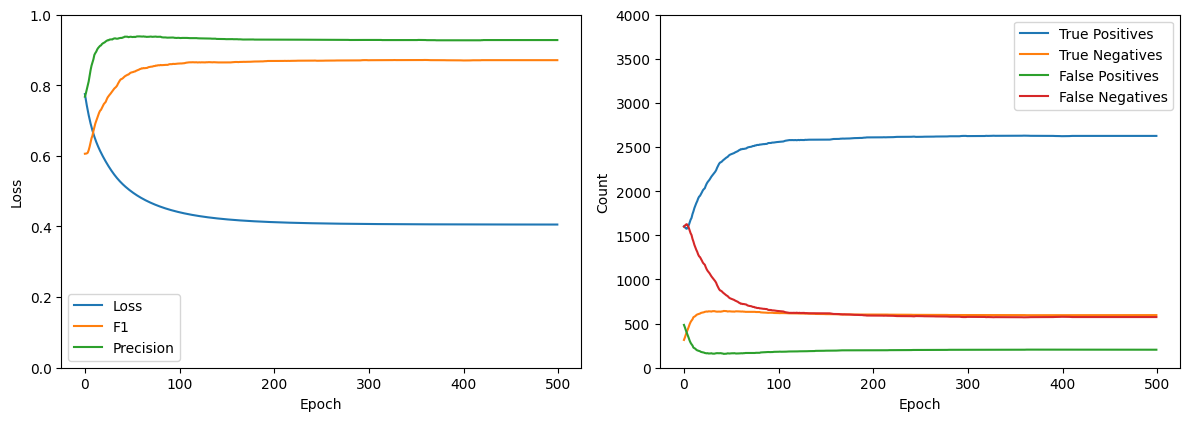

In [52]:
def visualize_eval(losses, true_positives, true_negatives, false_positives, false_negatives, f1_eval, precision_eval):
  plt.figure(figsize=(12, 8))
  plt.subplot(2, 2, 1)
  plt.plot(losses.numpy(), label='Loss')
  plt.plot(f1_eval.numpy(), label='F1')
  plt.plot(precision_eval.numpy(), label='Precision')
  plt.xlabel('Epoch')
  plt.ylabel('Loss')
  plt.ylim(0, 1)
  plt.legend()

  plt.subplot(2, 2, 2)
  plt.plot(true_positives.numpy(), label='True Positives')
  plt.plot(true_negatives.numpy(), label='True Negatives')
  plt.plot(false_positives.numpy(), label='False Positives')
  plt.plot(false_negatives.numpy(), label='False Negatives')
  plt.xlabel('Epoch')
  plt.ylabel('Count')
  plt.ylim(0, 4000)
  plt.legend()
  plt.tight_layout()
  plt.show()

model = logistic_regression_model(df_train.shape[1]-1)
losses, true_positives, true_negatives, false_positives, false_negatives, f1_eval, precision_eval =\
train_and_evaluate_model(df_train, df_test, model, 500, 0.01)

visualize_eval(losses, true_positives, true_negatives, false_positives, false_negatives, f1_eval, precision_eval)